# Notebook 03 — XGBoost: walk-forward mensual BTC15m YES

Entrenamiento expansivo desde diciembre de 2025; validación mensual anterior al test; tests de mayo a octubre de 2026. Reentrenamiento, selección de hiperparámetros y umbrales de entrada por fold. Se corrige el filtro de ventana temporal del backtest original.

**Limitación:** PnL proxy con velas, sin verificación de ejecutabilidad.

Se comparan dos conjuntos de variables: A (BRTI) y B (BRTI + Kalshi). No se utiliza información de otros mercados.

El backtest usa el ask de la vela recién cerrada como aproximación de entrada, sin esperar un minuto adicional. No es una confirmación de ejecución.

Para comparar A y B sobre las mismas decisiones se exige bid/ask y spread válidos en ambos modelos, aunque A no utilice esos precios como predictores.

In [1]:
# %pip install xgboost scikit-learn pandas numpy matplotlib pyarrow
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, accuracy_score
from sklearn.isotonic import IsotonicRegression
from xgboost import XGBClassifier
from IPython.display import display

ROOT=Path('data/processed'); OUT=Path('data/modeling'); OUT.mkdir(parents=True,exist_ok=True)
SEED=42
MIN_KALSHI_AGE=0       # decisión al cierre de la vela
EMBARGO_SECONDS=900    # evitar que contratos cercanos a fronteras compartan horizonte de resolución
FEE_PER_SIDE=0.0  # tarifa por operación (entrada/salida), NO es la tarifa real de Kalshi
SLIPPAGE_PER_SIDE=0.0  # costo adicional hipotético por ejecución
MIN_TRADES_VALIDATION=20
PARAM_GRID=[
    dict(max_depth=2,learning_rate=0.04,min_child_weight=5,reg_lambda=5,subsample=0.85,colsample_bytree=0.9),
    dict(max_depth=3,learning_rate=0.03,min_child_weight=10,reg_lambda=10,subsample=0.85,colsample_bytree=0.9),
    dict(max_depth=4,learning_rate=0.025,min_child_weight=15,reg_lambda=20,subsample=0.85,colsample_bytree=0.9),
]
MIN_EDGE_THRESHOLDS=[0.01,0.02,0.03,0.05,0.08,0.10]
# (mínimo, máximo) de minutos restantes al vencimiento, inclusive.
TIME_WINDOWS = [(1, 14), (1, 5), (3, 7), (5, 10), (7, 14), (3, 10)]
# La ventaja se mide contra el ask YES y debe cubrir además costos de entrada.
# Los umbrales se eligen exclusivamente en validation.
path=next((p for p in [ROOT/'dataset_completo.parquet',ROOT/'dataset_completo.csv',Path('dataset_completo.parquet'),Path('dataset_completo.csv')] if p.exists()),None)
assert path is not None, 'No se encontró dataset_completo. Ejecutá Notebook 02 o corregí ROOT.'
df=pd.read_parquet(path) if path.suffix=='.parquet' else pd.read_csv(path)
print('Origen:',path,'| filas:',len(df),'| contratos:',df.ticker.nunique())


Origen: data/processed/dataset_completo.parquet | filas: 423135 | contratos: 30272


In [2]:

# Fold mensual: entrenamiento expansivo, validación del mes anterior,
# test del mes actual. Se exigen 4 meses completos iniciales de train.
INITIAL_TRAIN_MONTHS = 4
VALIDATION_MONTHS = 1
TEST_MONTHS = 1
START_TEST_MONTH = "2026-05"
END_TEST_MONTH = "2026-10"
EMBARGO_SECONDS = 900

def prepare_data(df):
    # Dos grupos de variables: subyacente solamente, y subyacente + Kalshi.
    brti = ['minutes_remaining', 'brti_distance_to_strike_pct',
            'brti_return_1m', 'ewma_volatility_bps_min']
    kalshi = brti + ['kalshi_yes_price_proxy', 'kalshi_spread']
    features = {'A_BRTI': brti, 'B_BRTI_Kalshi': kalshi}

    required = ['ticker', 'decision_ts', 'contract_start_ts', 'contract_close_ts',
                'target_yes', 'valid_for_training', 'kalshi_feature_candle_end_ts',
                'kalshi_yes_bid', 'kalshi_yes_ask'] + kalshi
    missing = sorted(set(required) - set(df.columns))
    assert not missing, f'Faltan columnas: {missing}'
    base = df.copy()
    for column in set(required) - {'ticker', 'valid_for_training'}:
        base[column] = pd.to_numeric(base[column], errors='coerce')
    if base.valid_for_training.dtype != bool:
        base['valid_for_training'] = base.valid_for_training.astype(str).str.lower().isin(['true', '1'])

    assert not base.duplicated(['ticker', 'decision_ts']).any()
    assert base.groupby('ticker').contract_start_ts.nunique().max() == 1
    assert base.groupby('ticker').target_yes.nunique().max() == 1
    base = base.loc[
        base.valid_for_training &
        base.target_yes.isin([0, 1]) &
        base.minutes_remaining.gt(0) &
        base.decision_ts.ge(base.contract_start_ts) &
        base.decision_ts.lt(base.contract_close_ts) &
        base.kalshi_feature_candle_end_ts.eq(base.decision_ts)
    ].copy()
    base = base.replace([np.inf, -np.inf], np.nan).dropna(subset=kalshi)
    base = base.loc[
        base.kalshi_yes_bid.between(0, 1) &
        base.kalshi_yes_ask.between(0, 1) &
        base.kalshi_yes_bid.le(base.kalshi_yes_ask)
    ]
    base = base.sort_values(['contract_start_ts', 'ticker', 'decision_ts']).reset_index(drop=True)
    assert not base.empty, 'No quedaron observaciones válidas para entrenar.'
    return base, features

def monthly_folds(base):
    # UTC month boundaries, independent of arbitrary row percentages.
    contract=base[['ticker','contract_start_ts','contract_close_ts']].drop_duplicates('ticker')
    assert contract.ticker.is_unique
    months=pd.period_range(START_TEST_MONTH,END_TEST_MONTH,freq='M')
    for month in months:
        test_start=pd.Timestamp(month.start_time,tz='UTC').timestamp()
        test_end=pd.Timestamp((month+1).start_time,tz='UTC').timestamp()
        val_start=pd.Timestamp((month-VALIDATION_MONTHS).start_time,tz='UTC').timestamp()
        train_start=pd.Timestamp((pd.Period(START_TEST_MONTH,freq='M')-VALIDATION_MONTHS-INITIAL_TRAIN_MONTHS).start_time,tz='UTC').timestamp()
        # No contrato que cierra en / después de frontera puede entrar en el bloque previo.
        train_ids=contract.loc[(contract.contract_start_ts>=train_start)&
            (contract.contract_close_ts<=val_start-EMBARGO_SECONDS),'ticker']
        val_ids=contract.loc[(contract.contract_start_ts>=val_start+EMBARGO_SECONDS)&
            (contract.contract_close_ts<=test_start-EMBARGO_SECONDS),'ticker']
        test_ids=contract.loc[(contract.contract_start_ts>=test_start+EMBARGO_SECONDS)&
            (contract.contract_close_ts<=test_end),'ticker']
        parts={k:base.loc[base.ticker.isin(ids)].sort_values(
            ['ticker','decision_ts'],kind='stable').reset_index(drop=True)
            for k,ids in [('train',train_ids),('validation',val_ids),('test',test_ids)]}
        assert all(set(parts[a].ticker).isdisjoint(parts[b].ticker)
                   for a,b in [('train','validation'),('train','test'),('validation','test')])
        for k,p in parts.items():
            assert not p.empty, f"Fold {month}: {k} vacío; verificar cobertura histórica"
            assert p.target_yes.nunique()==2, f"Fold {month}: {k} sin ambas clases"
        yield str(month),parts

def weights_by_contract(d):
    w=1/d.groupby('ticker').ticker.transform('size').to_numpy(dtype=float)
    return w/w.mean()

def metric_row(model,month,part,prob):
    y=part.target_yes.astype(int).to_numpy()
    p=np.clip(np.asarray(prob),1e-7,1-1e-7)
    w=weights_by_contract(part)
    return dict(model=model,fold=month,rows=len(part),contracts=part.ticker.nunique(),
        logloss=log_loss(y,p,labels=[0,1]),
        weighted_logloss=log_loss(y,p,labels=[0,1],sample_weight=w),
        brier=brier_score_loss(y,p),
        weighted_brier=np.average((y-p)**2,weights=w),
        auc=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan)

def choose_strategy(make_frame,simulate,va,pva,min_trades):
    frame=make_frame(va,pva)
    candidates=[]
    for tmin,tmax in TIME_WINDOWS:
        for edge in MIN_EDGE_THRESHOLDS:
            t=simulate(frame,edge,tmin,tmax)
            if len(t)>=min_trades:
                candidates.append(dict(min_edge=edge,t_min=tmin,t_max=tmax,
                                       n=len(t),pnl=float(t.pnl_proxy.sum())))
    if not candidates: return None
    best=max(candidates,key=lambda x:(x['pnl'],x['n'],x['min_edge']))
    return {k:best[k] for k in ['min_edge','t_min','t_max']}

def show_results(all_trades,all_metrics,out):
    metrics=pd.DataFrame(all_metrics)
    trades=pd.concat(all_trades,ignore_index=True) if all_trades else pd.DataFrame()
    metrics.to_csv(out/'metricas_walkforward.csv',index=False)
    if trades.empty:
        print('No se seleccionaron operaciones de TEST'); return
    trades=trades.sort_values(['model','exit_ts','ticker']).reset_index(drop=True)
    trades['pnl_acumulado']=trades.groupby('model').pnl_proxy.cumsum()
    trades.to_csv(out/'operaciones_test_walkforward.csv',index=False)
    summary=trades.groupby('model').agg(operaciones=('ticker','size'),
        pnl_total=('pnl_proxy','sum'),pnl_medio=('pnl_proxy','mean'),
        win_rate=('pnl_proxy',lambda x:(x>0).mean()))
    display(summary.round(5))
    fig,ax=plt.subplots(figsize=(14,6))
    for name,g in trades.groupby('model'):
        dt=pd.to_datetime(g.exit_ts,unit='s',utc=True)
        ax.step(dt,g.pnl_acumulado,where='post',label=name)
    ax.axhline(0,color='gray',ls='--',lw=1)
    ax.set(title='PnL acumulado TEST walk-forward (proxy, NO ejecutable)',
           xlabel='Liquidación UTC',ylabel='PnL acumulado por contrato')
    ax.grid(alpha=.25);ax.legend();fig.autofmt_xdate()
    fig.tight_layout();fig.savefig(out/'pnl_walkforward.png',dpi=170);plt.show()
    fig,ax=plt.subplots(figsize=(13,5))
    for name,g in metrics.groupby('model'):
        ax.plot(g.fold,g.weighted_logloss,marker='o',label=name)
    ax.set(title='Log loss fuera de muestra por mes',xlabel='Mes TEST',ylabel='Log loss ponderado')
    ax.legend();ax.grid(alpha=.25);fig.tight_layout()
    fig.savefig(out/'logloss_walkforward.png',dpi=170);plt.show()
    display(metrics.round(5))


In [3]:
# Estrategia long-only YES: una entrada por contrato, sin salida anticipada.
def make_trade_frame(part, name, probs):
    out=part[['ticker','decision_ts','contract_close_ts','target_yes',
              'kalshi_yes_bid','kalshi_yes_ask','kalshi_yes_price_proxy','minutes_remaining']].copy().reset_index(drop=True)
    out['p_model']=np.asarray(probs,dtype=float)
    out['yes_bid']=pd.to_numeric(out.kalshi_yes_bid,errors='coerce')
    out['yes_ask']=pd.to_numeric(out.kalshi_yes_ask,errors='coerce')
    out['kalshi_reference']=pd.to_numeric(out.kalshi_yes_price_proxy,errors='coerce')
    out=out.loc[out.yes_bid.between(0,1)&out.yes_ask.between(0,1)&
                (out.yes_bid<=out.yes_ask)&out.p_model.between(0,1)].copy()
    return out.sort_values(['ticker','decision_ts'],kind='stable')

def simulate_strategy(frame,min_edge,t_min,t_max,
                      fee_per_side=FEE_PER_SIDE,slippage_per_side=SLIPPAGE_PER_SIDE):
    cost=float(fee_per_side+slippage_per_side)
    if cost<0: raise ValueError('Los costos no pueden ser negativos.')
    frame=frame.loc[frame.minutes_remaining.between(t_min,t_max)].copy()
    rows=[]
    # Filtramos por señales disponibles al momento de cada decisión.
    for ticker,g in frame.groupby('ticker',sort=False):
        for r in g.itertuples(index=False):
            edge=float(r.p_model-r.yes_ask)
            if edge < min_edge or edge < cost:
                continue
            capital=float(r.yes_ask+cost)
            if capital<=0: continue
            payoff=int(r.target_yes)
            pnl=payoff-capital
            rows.append(dict(ticker=ticker,side='YES',entry_ts=r.decision_ts,
                exit_ts=r.contract_close_ts,exit_reason='settlement',
                entry_ask=float(r.yes_ask),entry_p_model=float(r.p_model),
                entry_edge=edge,entry_cost=cost,capital=capital,
                kalshi_reference=float(r.kalshi_reference) if np.isfinite(r.kalshi_reference) else np.nan,
                target_yes=payoff,exit_proxy=payoff,pnl_proxy=pnl,
                realized_return=pnl/capital,
                expected_return_model=(float(r.p_model)-capital)/capital,
                expected_return_kalshi=(float(r.kalshi_reference)-capital)/capital
                    if np.isfinite(r.kalshi_reference) else np.nan))
            break
    return pd.DataFrame(rows)




Fold 2026-05: train 9,293 / validation 2,621 / test 2,730 contratos
A_BRTI | val logloss 0.4561 | trades 1677 | pnl proxy -19.146
B_BRTI_Kalshi | val logloss 0.4367 | trades 1919 | pnl proxy -25.121

Fold 2026-06: train 11,915 / validation 2,729 / test 2,635 contratos
A_BRTI | val logloss 0.4553 | trades 682 | pnl proxy 4.72
B_BRTI_Kalshi | val logloss 0.4363 | trades 195 | pnl proxy 7.35

Fold 2026-07: train 14,646 / validation 2,634 / test 2,758 contratos
A_BRTI | val logloss 0.4431 | trades 1508 | pnl proxy 23.232
B_BRTI_Kalshi | val logloss 0.4265 | trades 298 | pnl proxy 3.68

Fold 2026-08: train 17,282 / validation 2,758 / test 2,838 contratos
A_BRTI | val logloss 0.4572 | trades 1213 | pnl proxy 2.051
B_BRTI_Kalshi | val logloss 0.4377 | trades 1620 | pnl proxy 9.564

Fold 2026-09: train 20,042 / validation 2,838 / test 2,780 contratos
A_BRTI | val logloss 0.4707 | trades 2241 | pnl proxy -23.138
B_BRTI_Kalshi | val logloss 0.4477 | trades 563 | pnl proxy -0.088

Fold 2026-10: 

,operaciones,pnl_total,pnl_medio,win_rate
model,,,,
A_BRTI,8806,-29.180,-0.00331,0.45980
B_BRTI_Kalshi,5620,-32.772,-0.00583,0.61673


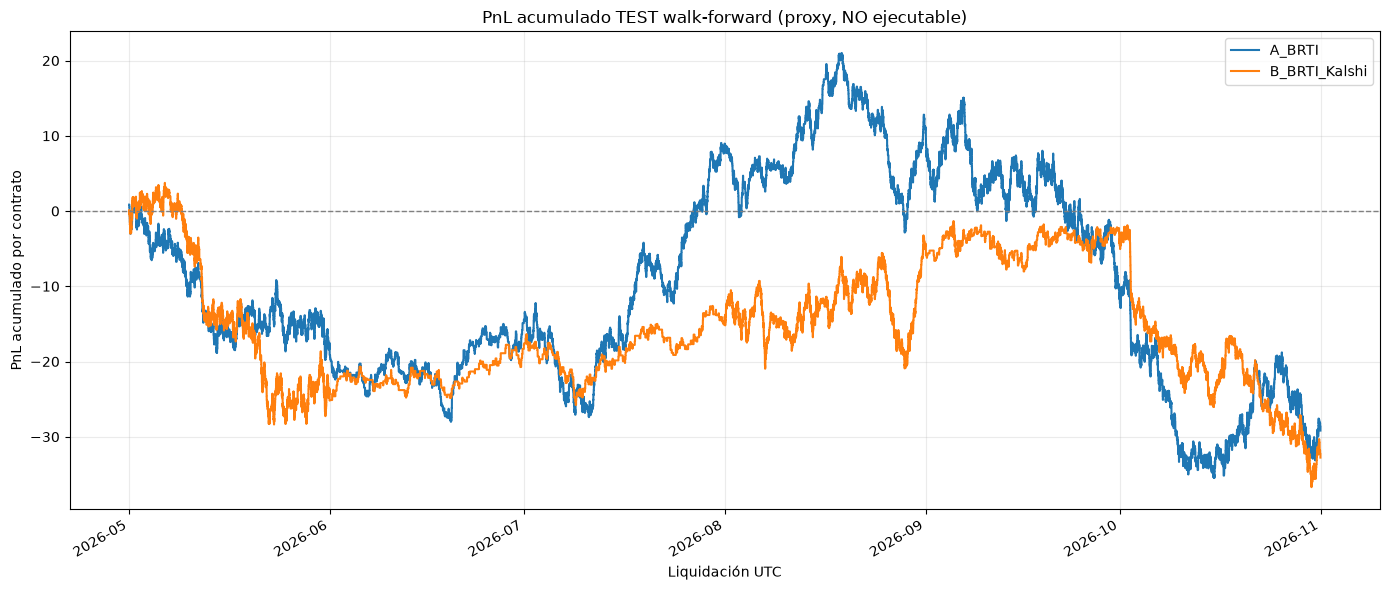

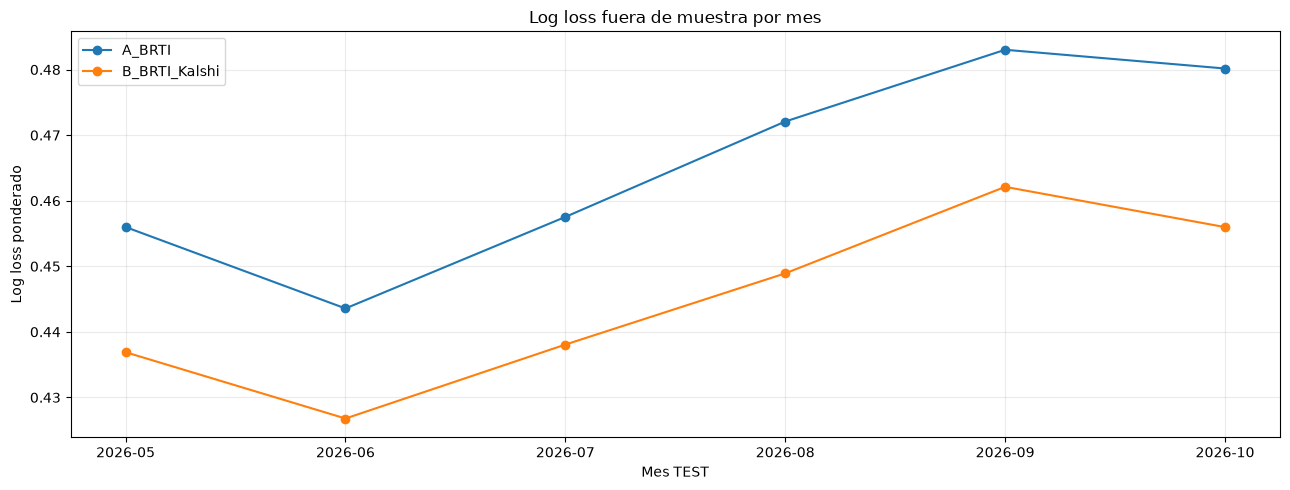

,model,fold,rows,contracts,logloss,weighted_logloss,brier,weighted_brier,auc
0,A_BRTI,2026-05,37478,2730,0.45783,0.45598,0.15268,0.15201,0.86037
1,B_BRTI_Kalshi,2026-05,37478,2730,0.43896,0.43689,0.14611,0.14543,0.87208
2,A_BRTI,2026-06,36293,2635,0.44415,0.44357,0.14760,0.14742,0.86879
3,B_BRTI_Kalshi,2026-06,36293,2635,0.42716,0.42678,0.14164,0.14154,0.87916
4,A_BRTI,2026-07,38127,2758,0.45697,0.45753,0.15286,0.15307,0.85975
5,B_BRTI_Kalshi,2026-07,38127,2758,0.43686,0.43806,0.14595,0.14635,0.87196
6,A_BRTI,2026-08,39390,2838,0.47203,0.47208,0.15731,0.15735,0.85155
7,B_BRTI_Kalshi,2026-08,39390,2838,0.44877,0.44892,0.14922,0.14928,0.86633
8,A_BRTI,2026-09,38682,2780,0.48201,0.48302,0.16175,0.16207,0.84354
9,B_BRTI_Kalshi,2026-09,38682,2780,0.46164,0.46212,0.15457,0.15475,0.85632


AVISO: asks de velas históricas no verifican cotizaciones ejecutables, tarifas ni liquidez.


In [4]:

base,models_features=prepare_data(df)
OUT=Path('data/modeling/walkforward_xgboost');OUT.mkdir(parents=True,exist_ok=True)
all_trades=[];all_metrics=[];all_configs=[]
last_fold_models={}
for month,parts in monthly_folds(base):
    tr,va,te=(parts[s] for s in ('train','validation','test'))
    print(f"\nFold {month}: train {tr.ticker.nunique():,} / validation {va.ticker.nunique():,} / test {te.ticker.nunique():,} contratos")
    for name,features in models_features.items():
        wtr,wva=weights_by_contract(tr),weights_by_contract(va)
        best=None
        for gid,params in enumerate(PARAM_GRID):
            model=XGBClassifier(n_estimators=1500,objective='binary:logistic',
                eval_metric='logloss',tree_method='hist',random_state=SEED,
                n_jobs=-1,early_stopping_rounds=75,**params)
            model.fit(tr[features],tr.target_yes.astype(int),sample_weight=wtr,
                eval_set=[(va[features],va.target_yes.astype(int))],
                sample_weight_eval_set=[wva],verbose=False)
            pval=np.clip(model.predict_proba(va[features])[:,1],1e-7,1-1e-7)
            score=log_loss(va.target_yes,pval,labels=[0,1],sample_weight=wva)
            if best is None or score<best[0]:
                best=(score,gid,model,pval)
        score,gid,model,pval=best
        ptest=np.clip(model.predict_proba(te[features])[:,1],1e-7,1-1e-7)
        all_metrics.append(metric_row(name,month,te,ptest))
        if month == END_TEST_MONTH:
            last_fold_models[name] = dict(
                grid_id=gid, n_estimators=int(model.best_iteration)+1,
                validation_logloss=float(score), policy=None
            )
        choice=choose_strategy(lambda part,p:make_trade_frame(part,name,p),
            simulate_strategy,va,pval,MIN_TRADES_VALIDATION)
        if month == END_TEST_MONTH:
            last_fold_models[name]['policy'] = choice
        all_configs.append(dict(fold=month,model=name,grid_id=gid,
            validation_logloss=score,**(choice or {})))
        if choice is None:
            print(name,': sin configuración con suficientes trades en validation')
            continue
        trades=simulate_strategy(make_trade_frame(te,name,ptest),**choice)
        if not trades.empty:
            trades['fold']=month;trades['model']=name
            all_trades.append(trades)
        print(name,'| val logloss',round(score,4),'| trades',len(trades),
              '| pnl proxy',round(float(trades.pnl_proxy.sum()) if len(trades) else 0,3))
pd.DataFrame(all_configs).to_csv(OUT/'configuraciones_por_fold.csv',index=False)
show_results(all_trades,all_metrics,OUT)
print('AVISO: asks de velas históricas no verifican cotizaciones ejecutables, tarifas ni liquidez.')


## Modelos finales para noviembre

Entreno nuevamente A y B usando todos los contratos hasta el 31 de octubre. La configuración y cantidad de árboles vienen del último fold, que eligió los hiperparámetros usando septiembre como validación. Octubre se incorpora al entrenamiento final; no se usa para elegir los parámetros. Se guardan el modelo, sus features y la política de inversión.

In [5]:
FINAL_DIR = OUT / 'modelos_para_noviembre'
FINAL_DIR.mkdir(parents=True, exist_ok=True)
FINAL_CUTOFF = pd.Timestamp('2026-11-01', tz='UTC').timestamp()
final_data = base.loc[base.contract_close_ts < FINAL_CUTOFF].copy()
assert not final_data.empty
assert set(last_fold_models) == set(models_features)

for name, features in models_features.items():
    selected = last_fold_models[name]
    params = PARAM_GRID[selected['grid_id']]
    model = XGBClassifier(
        n_estimators=selected['n_estimators'],
        objective='binary:logistic', eval_metric='logloss',
        tree_method='hist', random_state=SEED, n_jobs=-1,
        **params
    )
    model.fit(final_data[features], final_data.target_yes.astype(int),
              sample_weight=weights_by_contract(final_data))
    model_path = FINAL_DIR / f'{name}_final_octubre.json'
    model.save_model(str(model_path))
    metadata = {
        'features': features,
        'trained_through_exclusive_utc': '2026-11-01T00:00:00Z',
        'rows': len(final_data),
        'contracts': int(final_data.ticker.nunique()),
        'n_estimators': selected['n_estimators'],
        'hyperparameters': params,
        'selection': 'ultimo fold; validacion septiembre',
        'policy': selected['policy']
    }
    (FINAL_DIR / f'{name}_final_octubre_metadata.json').write_text(
        json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8'
    )
    print('Guardado:', model_path)


Guardado: data/modeling/walkforward_xgboost/modelos_para_noviembre/A_BRTI_final_octubre.json
Guardado: data/modeling/walkforward_xgboost/modelos_para_noviembre/B_BRTI_Kalshi_final_octubre.json
